# Beta = Cov / Var

**Da nuvem de pontos à reta de regressão — reprodução completa do Reel**

Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires) · [gabrielppires.com](https://gabrielppires.com) · setembro de 2026, revisado em outubro de 2026 com o vídeo em formato de código

---

O **beta** ($\beta$) mede quanto uma ação costuma se mover quando o mercado se move. Se o Ibovespa sobe 1% e a ação sobe, em média, 1,24%, o beta é 1,24. Este notebook calcula o beta passo a passo, mostra de onde vem a fórmula $\beta = \mathrm{Cov}/\mathrm{Var}$ e discute o que o beta **não** diz. No fim, usa o beta na mesa: o beta de uma carteira e o hedge com mini índice.

A seção 0 traz o código que aparece na tela do vídeo (30 linhas, os mesmos números). As equações têm a numeração da nota técnica, (1) a (10), a mesma do vídeo.

> Só educação. Não é recomendação de investimento.

## 0. O código da tela

As 30 linhas que o vídeo digita, sem tirar nada. Rodam sozinhas com o `base_ibov.xlsx` na mesma pasta e imprimem, na ordem: a reta de mínimos quadrados (2), as semanas no mesmo sentido e em sentidos opostos, o beta como Cov/Var (3), os betas de PETR4 e MGLU3, a decomposição β = ρ·σa/σm (5), o R² (6), o intervalo de confiança do beta de PETR4 (8), o beta móvel, o número de minicontratos do hedge (10) e a vol da carteira com e sem hedge. As seções seguintes refazem cada conta com calma.

In [1]:
import numpy as np, pandas as pd
X = pd.read_excel("base_ibov.xlsx", header=[0, 1], index_col=0)
T = ["^BVSP", "ITUB4.SA", "PETR4.SA", "MGLU3.SA"]   # 3 ações
S = X["Close"][T].resample("W-FRI").last()[:"2026-08-21"]  # sexta
R = S.pct_change()["2024-08-30":] * 100             # 104 semanas
m, a = R["^BVSP"], R["ITUB4.SA"]
print(np.polyfit(m, a, 1))                          # (2) a reta: β, α
dm, da = m - m.mean(), a - a.mean()
print(((dm * da) > 0).sum(), ((dm * da) < 0).sum()) # 92 e 12
cov = (dm * da).sum() / (len(m) - 1)                # 5,83 %²
var = (dm**2).sum() / (len(m) - 1)                  # 4,70 %²
print(cov / var)                                    # (3) 1,24
beta = lambda t: R[t].cov(m) / m.var()
print(beta("PETR4.SA"), beta("MGLU3.SA"))           # 0,55 e 1,96
rho = R.corr()["^BVSP"]; s = R.std() / m.std()
print(rho * s)                                      # (5) β = ρ × σa/σm
print(rho**2)                                       # (6) R²: 74, 10, 30 %
ep = lambda t: np.sqrt((1 - rho[t]**2) / (len(m) - 2)) * s[t]  # (8)
print(beta("PETR4.SA") + np.array([-1, 1]) * 1.98 * ep("PETR4.SA"))
H = S.pct_change().dropna()                         # desde 2020
h = H["^BVSP"].rolling(52)                          # janela de 1 ano
bm = H["PETR4.SA"].rolling(52).cov(H["^BVSP"]) / h.var()
print(bm.min(), bm.max())                           # 0,34 e 1,62
w = {"ITUB4.SA": .5, "PETR4.SA": .3, "MGLU3.SA": .2}
bp = sum(q * beta(t) for t, q in w.items())         # (9) 1,18
ib = X["Close"]["^BVSP"].iloc[-1]                   # 174.586 pontos
print(bp * 500_000 / (ib * 0.20))                   # (10) 17 minis
p = R[list(w)] @ pd.Series(w)                       # a carteira
v = lambda r: r.std() * 52**.5                      # vol anual, %
print(v(p), v(p - bp * m))                          # 21,8 e 11,6

[1.24099165 0.07812082]
92 12
1.240991645086829
0.5519656279917173 1.9583444015930869
Ticker
^BVSP       1.000000
ITUB4.SA    1.240992
PETR4.SA    0.551966
MGLU3.SA    1.958344
dtype: float64
Ticker
^BVSP       1.000000
ITUB4.SA    0.738956
PETR4.SA    0.103293
MGLU3.SA    0.303016
Name: ^BVSP, dtype: float64
[0.23312961 0.87080164]
0.33806306857919693 1.6213421160665733
16.8649604100493
21.771628563608164 11.623062711717907


## 1. Bibliotecas e parâmetros

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ARQUIVO = "/project/base_ibov.xlsx"
if not os.path.exists(ARQUIVO):
    ARQUIVO = "base_ibov.xlsx"

MERCADO = "^BVSP"
ACOES = {"ITUB4.SA": "ITUB4", "PETR4.SA": "PETR4", "MGLU3.SA": "MGLU3"}
ULTIMA_SEMANA = "2026-08-21"   # última sexta-feira completa no arquivo
INICIO = "2024-08-30"          # 104 semanas ≈ 2 anos

# paleta de gabrielppires.com: fundo branco, tinta marinho, azul, dourado e vermelho
BG, WHITE, GREY, CYAN, AMBER, PINK = "#FFFFFF", "#1B2A4A", "#6B7590", "#1E56B8", "#B7791F", "#B42318"
CORES = {"ITUB4": CYAN, "PETR4": AMBER, "MGLU3": PINK}       # as mesmas do vídeo
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GREY, "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "text.color": WHITE, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "DejaVu Sans", "figure.figsize": (8, 6), "figure.dpi": 110,
    "axes.grid": True, "grid.color": "#DDE1EC", "grid.linewidth": 0.8, "axes.titleweight": "bold", "axes.titlecolor": WHITE,
})

## 2. Leitura dos preços

A planilha tem o formato exportado pelo `yfinance`, com **duas linhas de cabeçalho**:

- a 1ª linha diz o campo: `Close`, `High`, `Low`, `Open`, `Volume`;
- a 2ª linha diz o ticker: `ITUB4.SA`, `^BVSP` etc.

Com `header=[0, 1]`, o pandas monta um `MultiIndex` e `df["Close"]` devolve só os fechamentos. A linha "Date" do cabeçalho vira um índice inválido e é descartada.

**Preços ajustados?** Para o beta, o ideal é usar preços **ajustados por proventos**. Com preços não ajustados, cada data ex-dividendo aparece como uma queda artificial. A célula abaixo lista as maiores variações diárias de cada ativo, para você conferir se alguma coincide com pagamento de dividendos.

In [3]:
bruto = pd.read_excel(ARQUIVO, header=[0, 1], index_col=0)
precos = bruto["Close"]
precos.index = pd.to_datetime(precos.index, errors="coerce")
precos = precos[precos.index.notna()].astype(float)

tickers = [MERCADO] + list(ACOES)
px = precos[tickers]
print(f"{px.shape[0]} pregões | {px.index.min():%d/%m/%Y} a {px.index.max():%d/%m/%Y} | faltantes: {px.isna().sum().to_dict()}")

ret_d = px.pct_change()
for t in tickers:
    top = ret_d[t].abs().nlargest(3)
    print(f"{t:>9}: " + " | ".join(f"{d:%d/%m/%y} {ret_d.loc[d, t]*100:+.1f}%" for d in top.index))

1657 pregões | 02/01/2020 a 26/08/2026 | faltantes: {'^BVSP': 0, 'ITUB4.SA': 0, 'PETR4.SA': 0, 'MGLU3.SA': 0}
    ^BVSP: 12/03/20 -14.8% | 16/03/20 -13.9% | 13/03/20 +13.9%
 ITUB4.SA: 04/10/21 -18.0% | 13/03/20 +11.1% | 12/03/20 -9.8%
 PETR4.SA: 09/03/20 -29.7% | 13/03/20 +22.2% | 22/02/21 -20.7%
 MGLU3.SA: 16/11/23 +25.1% | 07/11/23 +23.8% | 13/03/20 +23.5%


## 3. Retornos semanais

O vídeo usa **retornos semanais** (sexta a sexta) dos últimos 2 anos, que dão 104 observações. Os motivos:

- **Menos ruído:** retornos diários têm muito movimento que não tem a ver com o mercado.
- **Sincronia:** ações menos líquidas às vezes reagem ao mercado com atraso de um dia. No diário isso achata o beta; no semanal, o efeito se dilui.
- **Visual:** cerca de 100 pontos formam um scatter legível; 500 pontos diários viram uma mancha.

**Detalhes técnicos**

- `resample("W-FRI").last()` pega o último preço de cada semana, terminando na sexta. Se a sexta for feriado, entra o último pregão da semana.
- A última semana do arquivo está **incompleta** (termina numa quarta, 26/08), então cortamos em 21/08.
- Usamos retorno **simples**, $r_t = P_t/P_{t-1} - 1$, em %.

In [4]:
px_sem = px.resample("W-FRI").last()
px_sem = px_sem[px_sem.index <= ULTIMA_SEMANA]
R = px_sem.pct_change().loc[INICIO:] * 100
R = R.rename(columns={MERCADO: "IBOV", **ACOES})
print(f"{len(R)} semanas | {R.index[0]:%d/%m/%Y} a {R.index[-1]:%d/%m/%Y}")
R.describe().round(2)

104 semanas | 30/08/2024 a 21/08/2026


Ticker,IBOV,ITUB4,PETR4,MGLU3
count,104.00,104.00,104.00,104.00
mean,0.25,0.38,0.45,-0.76
std,2.17,3.13,3.72,7.71
min,-4.99,-8.19,-7.81,-18.23
25%,-1.10,-1.36,-1.86,-5.28
50%,0.15,0.34,0.58,-2.32
75%,1.93,2.21,2.92,4.27
max,8.53,10.00,9.64,22.14


## 4. O scatter e a reta de regressão

Cada ponto é uma semana:

- **eixo x:** retorno do Ibovespa ($r_m$);
- **eixo y:** retorno da ação ($r_a$).

A reta que melhor atravessa essa nuvem, no sentido de **mínimos quadrados** (menor soma dos quadrados das distâncias verticais), é o **modelo de mercado**:

$$
r_{a,t} = \alpha + \beta\, r_{m,t} + \varepsilon_t \tag{1}
$$

- $\beta$: inclinação. Quantos % a ação anda, em média, para cada 1% do índice.
- $\alpha$: intercepto. O retorno médio da ação quando o índice fica parado.
- $\varepsilon_t$: o que sobra, ou seja, o movimento **específico** da empresa naquela semana.

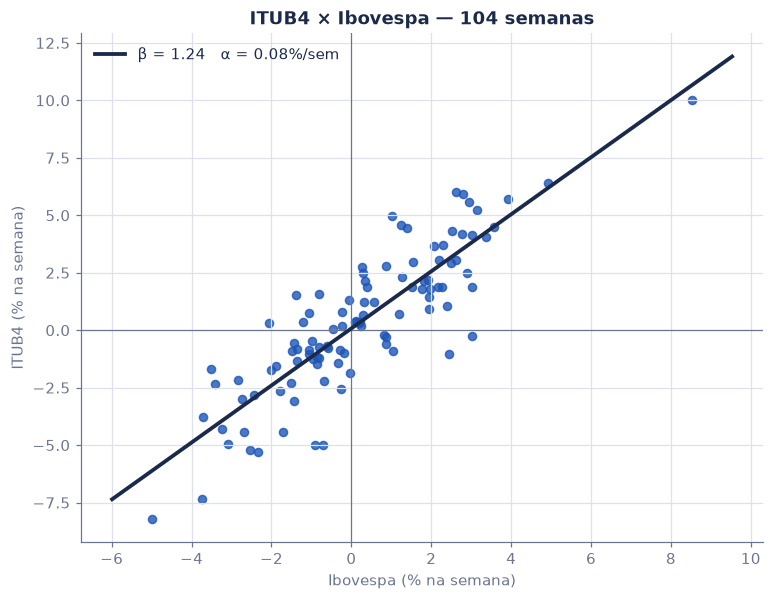

In [5]:
x, y = R["IBOV"], R["ITUB4"]
beta = np.cov(y, x, ddof=1)[0, 1] / x.var(ddof=1)
alpha = y.mean() - beta * x.mean()

fig, ax = plt.subplots()
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ax.scatter(x, y, s=28, color=CYAN, alpha=0.8)
xx = np.linspace(x.min() - 1, x.max() + 1, 50)
ax.plot(xx, alpha + beta * xx, color=WHITE, lw=2.5, label=f"β = {beta:.2f}   α = {alpha:.2f}%/sem")
ax.set(xlabel="Ibovespa (% na semana)", ylabel="ITUB4 (% na semana)", title=f"ITUB4 × Ibovespa — {len(R)} semanas")
ax.legend(frameon=False)
plt.show()

## 5. Por que $\beta = \mathrm{Cov}/\mathrm{Var}$ (cena 3)

### 5.1 A dedução

Mínimos quadrados escolhe $\alpha$ e $\beta$ que minimizam

$$
S(\alpha,\beta) = \sum_t \left(r_{a,t} - \alpha - \beta\, r_{m,t}\right)^2 \tag{2}
$$

Derivando e igualando a zero:

- **Em relação a $\alpha$:** a reta passa pelo ponto das médias,

$$
\alpha = \bar r_a - \beta\,\bar r_m. \tag{4}
$$

- **Em relação a $\beta$**, substituindo o $\alpha$ acima:

$$
\beta = \frac{\sum_t (r_{m,t}-\bar r_m)(r_{a,t}-\bar r_a)}{\sum_t (r_{m,t}-\bar r_m)^2} = \frac{\mathrm{Cov}(r_a, r_m)}{\mathrm{Var}(r_m)} \tag{3}
$$

O fator $1/(n-1)$ aparece no numerador e no denominador e se cancela.

### 5.2 A intuição dos quadrantes

Trace uma cruz no ponto das médias $(\bar r_m, \bar r_a)$. Cada semana contribui para a covariância com o produto $(r_m - \bar r_m)(r_a - \bar r_a)$:

- **quadrantes "mesmo sentido"** (os dois acima ou os dois abaixo da média): produto **positivo**;
- **quadrantes "sentido oposto"**: produto **negativo**.

A covariância é a média desses produtos. Dividindo pela variância do mercado, a "unidade" do mercado sai da conta e sobra a inclinação.

In [6]:
dx, dy = x - x.mean(), y - y.mean()
prod = dx * dy
cov_manual = prod.sum() / (len(x) - 1)
var_manual = (dx ** 2).sum() / (len(x) - 1)

print(f"Cov(ITUB4, IBOV) = {cov_manual:.3f} %²")
print(f"Var(IBOV)        = {var_manual:.3f} %²")
print(f"β = Cov / Var    = {cov_manual/var_manual:.4f}")
print()
print(f"semanas no mesmo sentido: {(prod>0).sum()} | sentido oposto: {(prod<0).sum()}")
print(f"soma dos produtos positivos: {prod[prod>0].sum():.1f} | negativos: {prod[prod<0].sum():.1f}")

# conferência com mínimos quadrados via álgebra linear
X = np.column_stack([np.ones(len(x)), x])
a_ls, b_ls = np.linalg.lstsq(X, y, rcond=None)[0]
print(f"\nlstsq: α = {a_ls:.4f}, β = {b_ls:.4f}  (igual ao Cov/Var)")

Cov(ITUB4, IBOV) = 5.831 %²
Var(IBOV)        = 4.699 %²
β = Cov / Var    = 1.2410

semanas no mesmo sentido: 92 | sentido oposto: 12
soma dos produtos positivos: 611.9 | negativos: -11.3

lstsq: α = 0.0781, β = 1.2410  (igual ao Cov/Var)


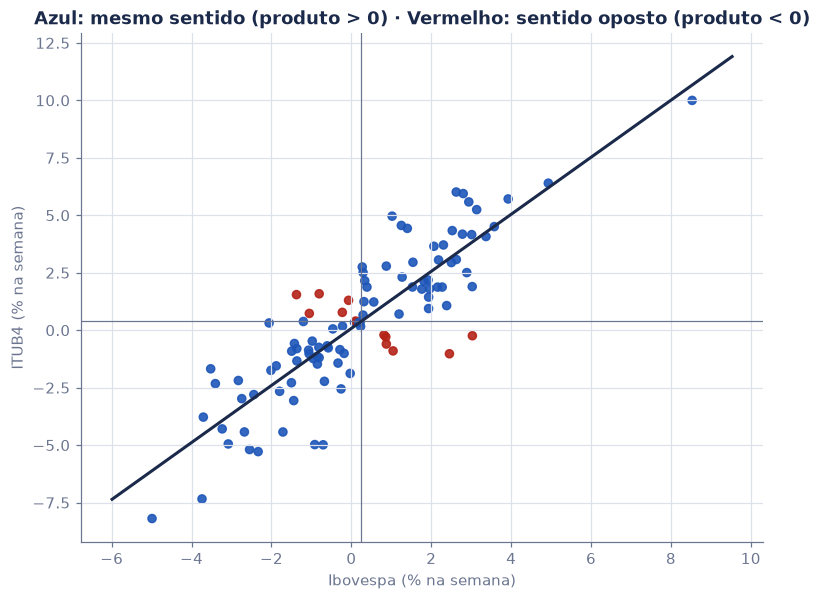

In [7]:
fig, ax = plt.subplots()
ax.axhline(y.mean(), color=GREY, lw=0.8); ax.axvline(x.mean(), color=GREY, lw=0.8)
ax.scatter(x, y, s=28, c=np.where(prod > 0, CYAN, PINK), alpha=0.9)
ax.plot(xx, alpha + beta * xx, color=WHITE, lw=2)
ax.set(xlabel="Ibovespa (% na semana)", ylabel="ITUB4 (% na semana)",
       title="Azul: mesmo sentido (produto > 0) · Vermelho: sentido oposto (produto < 0)")
plt.show()

## 6. Três ações, três betas

Mesma conta para três perfis diferentes:

- **ITUB4:** o maior banco da bolsa, com peso relevante no próprio Ibovespa.
- **PETR4:** muito ligada a petróleo e a decisões da empresa e do governo.
- **MGLU3:** varejo, muito sensível a juros e ao ciclo doméstico.

A linha tracejada de $\beta = 1$ é o "mercado puro". Acima dela a ação **amplifica** o índice; abaixo, **amortece**.

In [8]:
def estatisticas(a):
    xa, ya = R["IBOV"], R[a]
    b = np.cov(ya, xa, ddof=1)[0, 1] / xa.var(ddof=1)
    al = ya.mean() - b * xa.mean()
    rho = np.corrcoef(xa, ya)[0, 1]
    resid = ya - al - b * xa
    return {"β": b, "α_%sem": al, "ρ": rho, "R²": rho**2,
            "σ_ação_%sem": ya.std(ddof=1), "σ_ibov_%sem": xa.std(ddof=1),
            "σ_ação/σ_ibov": ya.std(ddof=1) / xa.std(ddof=1),
            "σ_resid_%sem": np.sqrt((resid**2).sum() / (len(xa) - 2))}

tab = pd.DataFrame({a: estatisticas(a) for a in ACOES.values()}).T
tab.round(3)

,β,α_%sem,ρ,R²,σ_ação_%sem,σ_ibov_%sem,σ_ação/σ_ibov,σ_resid_%sem
ITUB4,1.241,0.078,0.860,0.739,3.129,2.168,1.444,1.607
PETR4,0.552,0.316,0.321,0.103,3.723,2.168,1.717,3.542
MGLU3,1.958,-1.244,0.550,0.303,7.712,2.168,3.558,6.470


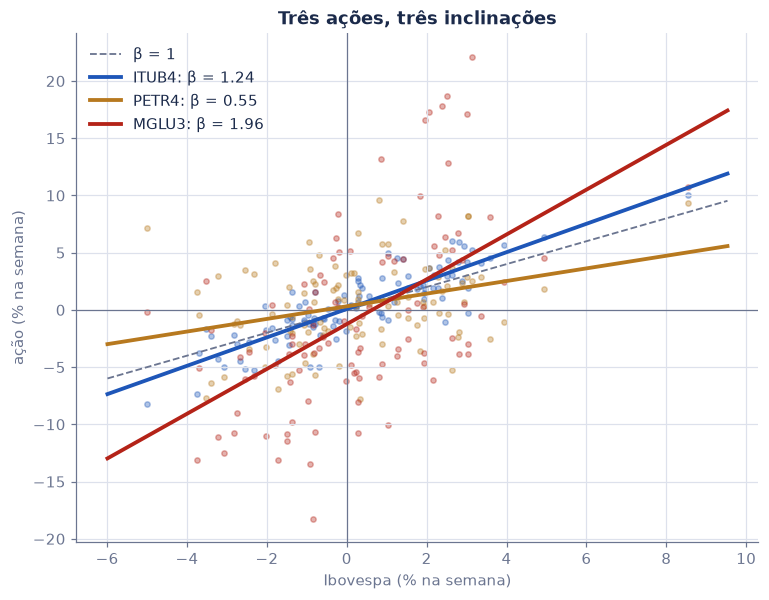

In [9]:
fig, ax = plt.subplots()
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ax.plot(xx, xx, ls="--", color=GREY, lw=1.2, label="β = 1")
for a in ACOES.values():
    ax.scatter(R["IBOV"], R[a], s=12, color=CORES[a], alpha=0.35)
    ax.plot(xx, tab.loc[a, "α_%sem"] + tab.loc[a, "β"] * xx, color=CORES[a], lw=2.5, label=f"{a}: β = {tab.loc[a, 'β']:.2f}")
ax.set(xlabel="Ibovespa (% na semana)", ylabel="ação (% na semana)", title="Três ações, três inclinações")
ax.legend(frameon=False)
plt.show()

## 7. Beta não é correlação

Reescrevendo a covariância como $\mathrm{Cov} = \rho\,\sigma_a\,\sigma_m$:

$$
\beta = \frac{\rho\,\sigma_a\,\sigma_m}{\sigma_m^2} = \rho \cdot \frac{\sigma_a}{\sigma_m} \tag{5}
$$

O beta é o produto de duas coisas diferentes:

1. **$\rho$ (correlação):** o quanto a ação *segue* o índice, entre −1 e 1.
2. **$\sigma_a/\sigma_m$:** o quanto a ação *oscila* em relação ao índice.

**No período analisado**

- **ITUB4** tem correlação alta (0,86) e oscila 1,4× o índice, o que dá β ≈ 1,24.
- **MGLU3** tem correlação menor (0,55), mas oscila 3,6× o índice. O resultado é β ≈ 1,96, **maior** que o de ITUB4 mesmo seguindo menos o mercado.
- **PETR4** tem correlação baixa (0,32), o que puxa o beta para baixo (0,55), embora ela oscile **mais** que o índice.

In [10]:
conf = tab[["ρ", "σ_ação/σ_ibov", "β"]].copy()
conf["ρ × σa/σm"] = conf["ρ"] * conf["σ_ação/σ_ibov"]
conf.round(4)

,ρ,σ_ação/σ_ibov,β,ρ × σa/σm
ITUB4,0.8596,1.4436,1.2410,1.2410
PETR4,0.3214,1.7174,0.5520,0.5520
MGLU3,0.5505,3.5576,1.9583,1.9583


## 8. Risco sistemático × específico

A variância da ação se divide em duas partes (propriedade da regressão por MQO):

$$
\sigma_a^2 = \underbrace{\beta^2\,\sigma_m^2}_{\text{sistemático (mercado)}} + \underbrace{\sigma_\varepsilon^2}_{\text{específico (empresa)}}, \qquad R^2 = \rho^2 \tag{6}
$$

A fração sistemática é exatamente o $R^2 = \rho^2$.

**Por que isso importa:** "beta baixo" **não** quer dizer "risco baixo". PETR4 tem beta baixo porque boa parte do risco dela é **específico** (petróleo, política de preços, governança), e não porque ela seja uma ação calma.

> Para o cálculo fechar exatamente, a variância residual abaixo usa o mesmo divisor $n-1$ das outras variâncias.

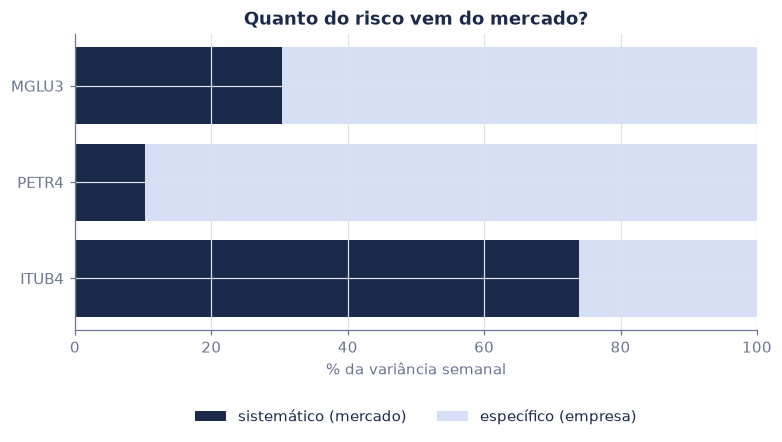

σ anual do Ibovespa no período: 15.6%


,σ²_total,sistemático,específico,% sistemático,σ_anual_%
ação,,,,,
ITUB4,9.79,7.24,2.56,73.90,22.57
PETR4,13.86,1.43,12.43,10.33,26.84
MGLU3,59.47,18.02,41.45,30.30,55.61


In [11]:
n = len(R)
linhas = []
for a in ACOES.values():
    b = tab.loc[a, "β"]; va = R[a].var(ddof=1); vm = R["IBOV"].var(ddof=1)
    resid = R[a] - tab.loc[a, "α_%sem"] - b * R["IBOV"]
    sist, esp = b**2 * vm, resid.var(ddof=1)
    linhas.append({"ação": a, "σ²_total": va, "sistemático": sist, "específico": esp,
                   "% sistemático": sist/va*100, "σ_anual_%": np.sqrt(va*52)})
risco = pd.DataFrame(linhas).set_index("ação")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(risco.index, risco["% sistemático"], color=WHITE, label="sistemático (mercado)")
ax.barh(risco.index, 100 - risco["% sistemático"], left=risco["% sistemático"], color="#D6E0F5", label="específico (empresa)")
ax.set(xlabel="% da variância semanal", xlim=(0, 100), title="Quanto do risco vem do mercado?")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
plt.show()
print(f"σ anual do Ibovespa no período: {np.sqrt(R['IBOV'].var(ddof=1)*52):.1f}%")
risco.round(2)

## 9. Quão confiável é o beta?

O beta é uma **estimativa**, e ela muda com a amostra. Três verificações:

### 9.1 Erro-padrão e intervalo de confiança

Na regressão simples:

$$
\hat\sigma_\varepsilon^2 = \frac{\sum \hat\varepsilon_t^2}{n-2} \tag{7}
$$

$$
EP(\hat\beta) = \sqrt{\frac{\hat\sigma_\varepsilon^2}{(n-1)\,\mathrm{Var}(r_m)}} = \sqrt{\frac{1-\rho^2}{n-2}}\;\frac{\sigma_a}{\sigma_m} \tag{8}
$$

A segunda forma é a que o vídeo digita: ela usa só a correlação e a razão das volatilidades.

O intervalo de 95% é aproximadamente $\hat\beta \pm 1{,}98 \cdot EP$ (t de Student com $n-2 = 102$ graus de liberdade).

In [12]:
try:
    from scipy import stats as st
    tcrit = st.t.ppf(0.975, n - 2)
except Exception:                     # sem scipy: bissecção na fda da t, pela beta incompleta (Numerical Recipes, 6.4)
    from math import lgamma, exp, log
    def _betacf(a, b, x):
        c, d = 1.0, 1 - (a + b) * x / (a + 1); d = 1 / d; f = d
        for m in range(1, 300):
            k = m * (b - m) * x / ((a + 2*m - 1) * (a + 2*m)); d = 1 / (1 + k * d); c = 1 + k / c; f *= c * d
            k = -(a + m) * (a + b + m) * x / ((a + 2*m) * (a + 2*m + 1)); d = 1 / (1 + k * d); c = 1 + k / c; f *= c * d
            if abs(c * d - 1) < 1e-14: break
        return f
    def _t_cdf(t, nu):
        x = nu / (nu + t * t); a, b = nu / 2, 0.5
        ib = exp(a * log(x) + b * log(1 - x) - (lgamma(a) + lgamma(b) - lgamma(a + b))) * _betacf(a, b, x) / a
        return 1 - ib / 2 if t > 0 else ib / 2
    lo, hi = 0.0, 10.0
    for _ in range(100):
        mid = (lo + hi) / 2; lo, hi = (mid, hi) if _t_cdf(mid, n - 2) < 0.975 else (lo, mid)
    tcrit = (lo + hi) / 2
print(f"t crítico (95%, {n - 2} g.l.) = {tcrit:.4f}")
ic = []
for a in ACOES.values():
    ep = tab.loc[a, "σ_resid_%sem"] / np.sqrt((n - 1) * R["IBOV"].var(ddof=1))
    b = tab.loc[a, "β"]
    ic.append({"ação": a, "β": b, "EP": ep, "IC95_inf": b - tcrit*ep, "IC95_sup": b + tcrit*ep})
pd.DataFrame(ic).set_index("ação").round(3)

t crítico (95%, 102 g.l.) = 1.9835


,β,EP,IC95_inf,IC95_sup
ação,,,,
ITUB4,1.241,0.073,1.096,1.386
PETR4,0.552,0.161,0.233,0.871
MGLU3,1.958,0.294,1.375,2.542


### 9.2 Frequência dos retornos

O mesmo período de 2 anos com retornos diários, semanais e mensais. Diferenças grandes entre as frequências sugerem atraso de reação ou pouca liquidez, ou apenas pouca amostra no caso mensal, que tem só cerca de 24 pontos.

In [13]:
def beta_freq(regra):
    if regra == "D":
        p = px.loc[:ULTIMA_SEMANA]
    else:
        p = px.resample(regra).last()
        p = p[p.index <= ULTIMA_SEMANA]
    r = p.pct_change().loc[INICIO:].dropna()
    return {ACOES[t]: np.cov(r[t], r[MERCADO], ddof=1)[0, 1] / r[MERCADO].var(ddof=1) for t in ACOES} | {"n": len(r)}

pd.DataFrame({"diário": beta_freq("D"), "semanal": beta_freq("W-FRI"), "mensal": beta_freq("ME")}).round(2)

,diário,semanal,mensal
ITUB4,1.11,1.24,1.23
PETR4,0.53,0.55,0.91
MGLU3,2.34,1.96,2.91
n,493.00,104.00,24.00


### 9.3 Beta móvel (52 semanas)

Recalculando o beta a cada semana com a janela das 52 semanas anteriores, usando todo o histórico do arquivo desde 2020. Se a linha oscila muito, o "beta da ação" depende bastante do período escolhido.

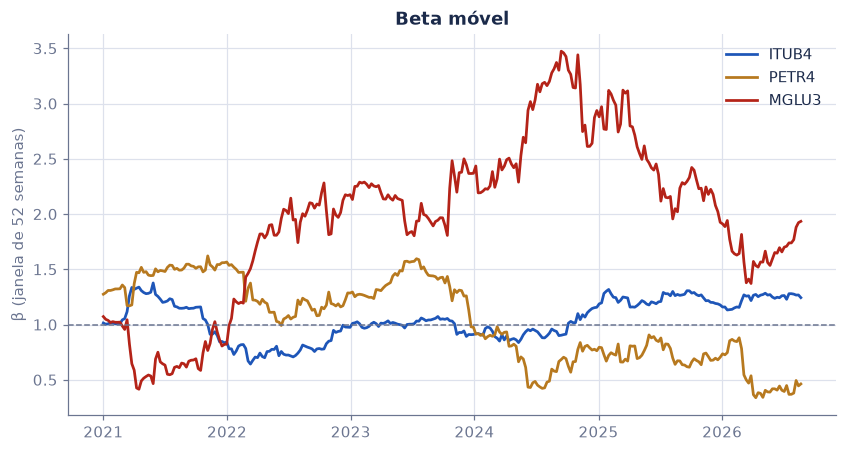

In [14]:
Rh = px.resample("W-FRI").last()
Rh = Rh[Rh.index <= ULTIMA_SEMANA].pct_change().dropna()
fig, ax = plt.subplots(figsize=(9, 4.5))
for t, a in ACOES.items():
    b_movel = Rh[t].rolling(52).cov(Rh[MERCADO]) / Rh[MERCADO].rolling(52).var()
    ax.plot(b_movel.index, b_movel, color=CORES[a], lw=1.8, label=a)
ax.axhline(1, ls="--", color=GREY, lw=1)
ax.set(ylabel="β (janela de 52 semanas)", title="Beta móvel")
ax.legend(frameon=False)
plt.show()

## 10. Na mesa: o beta de uma carteira e o hedge

**Beta da carteira.** O retorno de uma carteira é a média ponderada dos retornos, e a covariância é linear. Então o beta da carteira é a média ponderada dos betas:

$$
\beta_p = \frac{\mathrm{Cov}\big(\sum_i w_i r_i,\ r_m\big)}{\mathrm{Var}(r_m)} = \sum_i w_i\,\beta_i. \tag{9}
$$

**Hedge com mini índice.** Para tirar a exposição ao mercado de uma carteira de valor $V$, vende-se o número de contratos que tem a mesma exposição em reais:

$$
N = \frac{\beta_p \times V}{\text{pontos do índice} \times \text{valor do ponto}}. \tag{10}
$$

No mini índice (WIN), cada ponto vale R\$ 0,20. O hedge que minimiza a variância da carteira protegida tem razão $h^* = \mathrm{Cov}(r_p, r_m)/\mathrm{Var}(r_m) = \beta_p$, e o que sobra é a fração $1 - \rho_p^2$ da variância: o risco próprio das empresas, que o índice não cobre.

O exemplo do vídeo: R\$ 500 mil com metade em ITUB4, 30% em PETR4 e 20% em MGLU3, rebalanceada toda semana.

In [15]:
W = {"ITUB4": 0.5, "PETR4": 0.3, "MGLU3": 0.2}
VALOR, VALOR_PONTO = 500_000, 0.20
beta_p = sum(W[a] * tab.loc[a, "β"] for a in W)                         # (9)
r_p = sum(W[a] * R[a] for a in W)                                          # carteira, % na semana
beta_p_reg = np.cov(r_p, R["IBOV"], ddof=1)[0, 1] / R["IBOV"].var(ddof=1)
pontos = px[MERCADO].iloc[-1]
N = beta_p * VALOR / (pontos * VALOR_PONTO)                                # (10)
r_h = r_p - beta_p * R["IBOV"]                                             # carteira com o hedge
rho_p = np.corrcoef(r_p, R["IBOV"])[0, 1]
vol = lambda r: r.std(ddof=1) * np.sqrt(52)
print(f"β da carteira = {' + '.join(f'{W[a]:.1f}×{tab.loc[a, chr(946)]:.2f}' for a in W)} = {beta_p:.4f} (regressão direta: {beta_p_reg:.4f})")
print(f"Ibovespa em {px.index[-1]:%d/%m/%Y}: {pontos:,.0f} pontos → um mini vale R$ {pontos * VALOR_PONTO:,.0f}".replace(",", "."))
print(f"N = {beta_p:.4f} × {VALOR:,} / ({pontos:,.0f} × {VALOR_PONTO}) = {N:.2f} → vender {round(N)} contratos".replace(",", "."))
print(f"vol anual: sem hedge {vol(r_p):.1f}% · com hedge {vol(r_h):.1f}% · sobra 1 − ρ² = {1 - rho_p**2:.3f} da variância (ρ = {rho_p:.3f})")

β da carteira = 0.5×1.24 + 0.3×0.55 + 0.2×1.96 = 1.1778 (regressão direta: 1.1778)
Ibovespa em 26/08/2026: 174.586 pontos → um mini vale R$ 34.917
N = 1.1778 × 500.000 / (174.586 × 0.2) = 16.86 → vender 17 contratos
vol anual: sem hedge 21.8% · com hedge 11.6% · sobra 1 − ρ² = 0.285 da variância (ρ = 0.846)


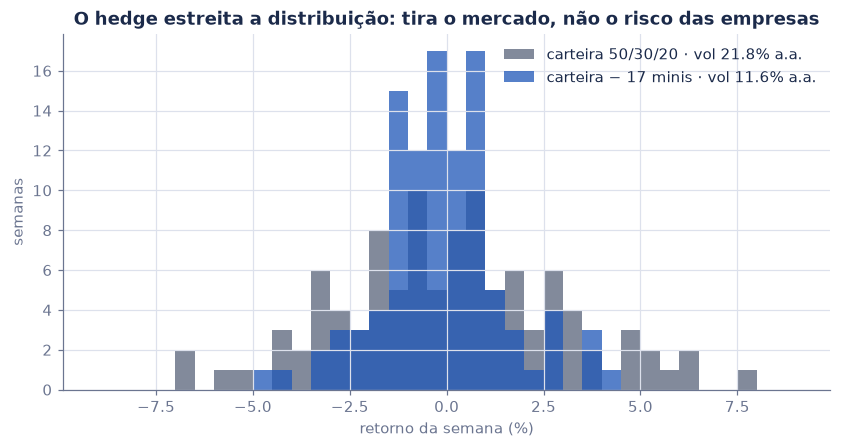

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(-9, 9, 37)
ax.hist(r_p, bins=bins, color=WHITE, alpha=0.55, label=f"carteira 50/30/20 · vol {vol(r_p):.1f}% a.a.")
ax.hist(r_h, bins=bins, color=CYAN, alpha=0.75, label=f"carteira − {round(N)} minis · vol {vol(r_h):.1f}% a.a.")
ax.set(xlabel="retorno da semana (%)", ylabel="semanas", title="O hedge estreita a distribuição: tira o mercado, não o risco das empresas")
ax.legend(frameon=False)
plt.show()

**Leitura.** O hedge corta a volatilidade quase pela metade, mas não a zera: sobra o risco específico, a fração $1 - \rho_p^2$ da variância. E o hedge é tão bom quanto o beta usado: com o intervalo de confiança da seção 9, o beta da carteira poderia estar alguns décimos acima ou abaixo, e o número de contratos muda junto. Na prática, a mesa refaz a conta com frequência e acompanha o beta móvel.

> A série com hedge subtrai o retorno do índice à vista. Um futuro de verdade rende o índice menos o custo de carregamento (CDI menos dividendos), então a carteira protegida ganharia, em média, cerca de $eta_p$ vezes o CDI a mais do que a série acima sugere. Para medir risco, a diferença é pequena; para medir resultado, ela importa.

## 11. Os números do vídeo

Cada número que a narração fala ou a tela mostra, com a seção deste notebook e a equação da nota técnica.

In [17]:
fmt = lambda v, d=2: f"{v:.{d}f}"
resumo = pd.DataFrame([
    ("β ITUB4 (Cov / Var)", f"{cov_manual:.2f} / {var_manual:.2f} = {beta:.2f}", "5", "(3)"),
    ("semanas no mesmo sentido / opostas", f"{(prod > 0).sum()} / {(prod < 0).sum()}", "5", ""),
    ("β PETR4 e MGLU3", f"{tab.loc['PETR4', 'β']:.2f} e {tab.loc['MGLU3', 'β']:.2f}", "6", "(3)"),
    ("ρ e σa/σm (ITUB4, MGLU3)", f"{tab.loc['ITUB4', 'ρ']:.2f} × {tab.loc['ITUB4', 'σ_ação/σ_ibov']:.1f} · {tab.loc['MGLU3', 'ρ']:.2f} × {tab.loc['MGLU3', 'σ_ação/σ_ibov']:.1f}", "7", "(5)"),
    ("R² ITUB4 / MGLU3 / PETR4", " / ".join(f"{tab.loc[a, 'R²'] * 100:.0f}%" for a in ["ITUB4", "MGLU3", "PETR4"]), "8", "(6)"),
    ("vol anual ITUB4 / PETR4 / MGLU3", " / ".join(f"{risco.loc[a, 'σ_anual_%']:.1f}%" for a in ["ITUB4", "PETR4", "MGLU3"]), "8", ""),
    ("IC 95% do β de PETR4", f"{ic[1]['IC95_inf']:.2f} a {ic[1]['IC95_sup']:.2f}", "9.1", "(8)"),
    ("β móvel de PETR4 (52 semanas)", f"{(Rh['PETR4.SA'].rolling(52).cov(Rh[MERCADO]) / Rh[MERCADO].rolling(52).var()).min():.2f} a {(Rh['PETR4.SA'].rolling(52).cov(Rh[MERCADO]) / Rh[MERCADO].rolling(52).var()).max():.2f}", "9.3", ""),
    ("β da carteira 50/30/20", f"{beta_p:.2f}", "10", "(9)"),
    ("minicontratos para o hedge", f"{N:.1f} → {round(N)}", "10", "(10)"),
    ("vol anual sem / com hedge", f"{vol(r_p):.1f}% / {vol(r_h):.1f}%", "10", ""),
], columns=["número", "valor", "seção", "eq."]).set_index("número")
resumo

,valor,seção,eq.
número,,,
β ITUB4 (Cov / Var),5.83 / 4.70 = 1.24,5,(3)
semanas no mesmo sentido / opostas,92 / 12,5,
β PETR4 e MGLU3,0.55 e 1.96,6,(3)
"ρ e σa/σm (ITUB4, MGLU3)",0.86 × 1.4 · 0.55 × 3.6,7,(5)
R² ITUB4 / MGLU3 / PETR4,74% / 30% / 10%,8,(6)
vol anual ITUB4 / PETR4 / MGLU3,22.6% / 26.8% / 55.6%,8,
IC 95% do β de PETR4,0.23 a 0.87,9.1,(8)
β móvel de PETR4 (52 semanas),0.34 a 1.62,9.3,
β da carteira 50/30/20,1.18,10,(9)


---
Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires)

© {2026} · Conteúdo educacional. Não é recomendação de investimento.